In [1]:
# ── Install all required packages ──────────────────────────────────────────
# Run this once. The "quiet" flag suppresses verbose pip output.
!pip install yfinance pandas numpy scikit-learn xgboost lightgbm ta \
             imbalanced-learn matplotlib seaborn --quiet

# ── Standard library imports ────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')      # suppress noisy sklearn/ta warnings

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# ── Data download ───────────────────────────────────────────────────────────
import yfinance as yf

# ── Technical indicators (ta library) ───────────────────────────────────────
from ta.trend     import EMAIndicator, SMAIndicator, MACD, ADXIndicator, CCIIndicator
from ta.momentum  import RSIIndicator, StochasticOscillator, WilliamsRIndicator, ROCIndicator
from ta.volatility import BollingerBands, AverageTrueRange, KeltnerChannel
from ta.volume    import OnBalanceVolumeIndicator, VolumeWeightedAveragePrice

# ── Machine learning ─────────────────────────────────────────────────────────
from sklearn.ensemble        import RandomForestClassifier, VotingClassifier
from sklearn.preprocessing   import StandardScaler, RobustScaler
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics         import (classification_report, confusion_matrix,
                                     accuracy_score, f1_score)
from xgboost  import XGBClassifier
from lightgbm import LGBMClassifier

# ── Class imbalance fix ───────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

print("✅ All libraries imported successfully!")

  DEPRECATION: Building 'ta' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'ta'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.24.0 requires scikit-learn>=1.8.0, but you have scikit-learn 1.6.1 which is incompatible.


✅ All libraries imported successfully!


In [2]:
# ── All 50 Nifty 50 tickers in Yahoo Finance format (.NS suffix) ────────────
# These are the current constituents as of 2024-25.
# Yahoo Finance requires the ".NS" suffix for NSE-listed stocks.

NIFTY50 = [
    "RELIANCE.NS",  "TCS.NS",       "HDFCBANK.NS",  "INFY.NS",      "ICICIBANK.NS",
    "HINDUNILVR.NS","ITC.NS",       "SBIN.NS",      "BHARTIARTL.NS","KOTAKBANK.NS",
    "LT.NS",        "AXISBANK.NS",  "ASIANPAINT.NS","MARUTI.NS",    "TITAN.NS",
    "SUNPHARMA.NS", "ULTRACEMCO.NS","WIPRO.NS",     "NESTLEIND.NS", "POWERGRID.NS",
    "NTPC.NS",      "TATAMOTORS.NS","BAJFINANCE.NS","HCLTECH.NS",   "TECHM.NS",
    "ONGC.NS",      "JSWSTEEL.NS",  "TATASTEEL.NS", "ADANIENT.NS",  "ADANIPORTS.NS",
    "COALINDIA.NS", "DIVISLAB.NS",  "DRREDDY.NS",   "CIPLA.NS",     "BAJAJFINSV.NS",
    "BPCL.NS",      "HEROMOTOCO.NS","EICHERMOT.NS", "GRASIM.NS",    "HINDALCO.NS",
    "INDUSINDBK.NS","M&M.NS",       "BRITANNIA.NS", "APOLLOHOSP.NS","TATACONSUM.NS",
    "SBILIFE.NS",   "HDFCLIFE.NS",  "UPL.NS",       "BAJAJ-AUTO.NS","SHRIRAMFIN.NS"
]

# Human-readable label map used throughout the notebook
LABEL_MAP = {
    0: "Strongly Bearish",   # forward return < -3%
    1: "Mildly Bearish",     # forward return between -3% and 0%
    2: "Mildly Bullish",     # forward return between  0% and +3%
    3: "Strongly Bullish"    # forward return > +3%
}

print(f"✅ {len(NIFTY50)} tickers defined")
print(f"📋 Labels: {LABEL_MAP}")

✅ 50 tickers defined
📋 Labels: {0: 'Strongly Bearish', 1: 'Mildly Bearish', 2: 'Mildly Bullish', 3: 'Strongly Bullish'}


In [3]:
def download_all(tickers, period="10y", interval="1d"):
    """
    Downloads OHLCV data for every ticker.
    - period="10y"  → 10 years of history
    - interval="1d" → daily candles
    - Skips any ticker with fewer than 500 trading days (avoids newly listed stocks)
    - time.sleep(0.3) → polite delay so Yahoo Finance doesn't rate-limit us
    """
    data, failed = {}, []

    for i, t in enumerate(tickers, 1):
        try:
            df = yf.download(t, period=period, interval=interval,
                             auto_adjust=True,   # adjusts for splits & dividends
                             progress=False)

            # auto_adjust returns flat columns; drop any multi-index just in case
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)

            if len(df) >= 500:               # need enough rows for 200-day EMA
                data[t] = df
                print(f"  ✅ [{i:02d}/{len(tickers)}] {t:20s} {len(df)} rows")
            else:
                failed.append(t)
                print(f"  ⚠️  [{i:02d}/{len(tickers)}] {t:20s} too few rows ({len(df)})")

        except Exception as e:
            failed.append(t)
            print(f"  ❌ [{i:02d}/{len(tickers)}] {t:20s} ERROR: {e}")

        time.sleep(0.3)

    print(f"\n✅ Downloaded : {len(data)} stocks")
    print(f"❌ Failed     : {len(failed)} → {failed}")
    return data

raw_data = download_all(NIFTY50)

  ✅ [01/50] RELIANCE.NS          2470 rows
  ✅ [02/50] TCS.NS               2470 rows
  ✅ [03/50] HDFCBANK.NS          2470 rows
  ✅ [04/50] INFY.NS              2470 rows
  ✅ [05/50] ICICIBANK.NS         2470 rows
  ✅ [06/50] HINDUNILVR.NS        2470 rows
  ✅ [07/50] ITC.NS               2470 rows
  ✅ [08/50] SBIN.NS              2470 rows
  ✅ [09/50] BHARTIARTL.NS        2470 rows
  ✅ [10/50] KOTAKBANK.NS         2470 rows
  ✅ [11/50] LT.NS                2470 rows
  ✅ [12/50] AXISBANK.NS          2470 rows
  ✅ [13/50] ASIANPAINT.NS        2470 rows
  ✅ [14/50] MARUTI.NS            2470 rows
  ✅ [15/50] TITAN.NS             2470 rows
  ✅ [16/50] SUNPHARMA.NS         2470 rows
  ✅ [17/50] ULTRACEMCO.NS        2470 rows
  ✅ [18/50] WIPRO.NS             2470 rows
  ✅ [19/50] NESTLEIND.NS         2470 rows
  ✅ [20/50] POWERGRID.NS         2470 rows
  ✅ [21/50] NTPC.NS              2470 rows


HTTP Error 404: Not Found{"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TATAMOTORS.NS"}}}
$TATAMOTORS.NS: possibly delisted; no price data found  (period=10y) (Yahoo error = "No data found, symbol may be delisted")

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no price data found  (period=10y) (Yahoo error = "No data found, symbol may be delisted")


  ⚠️  [22/50] TATAMOTORS.NS        too few rows (0)
  ✅ [23/50] BAJFINANCE.NS        2470 rows
  ✅ [24/50] HCLTECH.NS           2470 rows
  ✅ [25/50] TECHM.NS             2470 rows
  ✅ [26/50] ONGC.NS              2470 rows
  ✅ [27/50] JSWSTEEL.NS          2470 rows
  ✅ [28/50] TATASTEEL.NS         2470 rows
  ✅ [29/50] ADANIENT.NS          2470 rows
  ✅ [30/50] ADANIPORTS.NS        2470 rows
  ✅ [31/50] COALINDIA.NS         2470 rows
  ✅ [32/50] DIVISLAB.NS          2470 rows
  ✅ [33/50] DRREDDY.NS           2470 rows
  ✅ [34/50] CIPLA.NS             2470 rows
  ✅ [35/50] BAJAJFINSV.NS        2470 rows
  ✅ [36/50] BPCL.NS              2470 rows
  ✅ [37/50] HEROMOTOCO.NS        2470 rows
  ✅ [38/50] EICHERMOT.NS         2470 rows
  ✅ [39/50] GRASIM.NS            2470 rows
  ✅ [40/50] HINDALCO.NS          2470 rows
  ✅ [41/50] INDUSINDBK.NS        2470 rows
  ✅ [42/50] M&M.NS               2470 rows
  ✅ [43/50] BRITANNIA.NS         2470 rows
  ✅ [44/50] APOLLOHOSP.NS        2470 rows
  

In [5]:
def build_features(df):
    """
    Adds 40+ technical indicators to a single stock's OHLCV dataframe.
    Every indicator is computed on a pandas Series (not a DataFrame column)
    to avoid shape mismatches that the 'ta' library sometimes raises.
    Returns the dataframe with NaN rows dropped (first ~200 rows lost to EMA-200 warmup).
    """
    df = df.copy()

    # Squeeze in case yfinance returns a 1-column DataFrame instead of a Series
    close  = df['Close'].squeeze()
    high   = df['High'].squeeze()
    low    = df['Low'].squeeze()
    volume = df['Volume'].squeeze()

    # ── TREND ────────────────────────────────────────────────────────────────
    # Exponential Moving Averages at 4 timeframes
    df['ema9']   = EMAIndicator(close, window=9).ema_indicator()
    df['ema21']  = EMAIndicator(close, window=21).ema_indicator()
    df['ema50']  = EMAIndicator(close, window=50).ema_indicator()
    df['ema200'] = EMAIndicator(close, window=200).ema_indicator()
    df['sma20']  = SMAIndicator(close, window=20).sma_indicator()

    # MACD: difference between fast and slow EMA; signal is a smoothed MACD
    _macd          = MACD(close, window_slow=26, window_fast=12, window_sign=9)
    df['macd']     = _macd.macd()
    df['macd_sig'] = _macd.macd_signal()
    df['macd_diff']= _macd.macd_diff()   # histogram (MACD minus signal)

    # ADX: measures TREND STRENGTH (not direction); > 25 = strong trend
    _adx        = ADXIndicator(high, low, close, window=14)
    df['adx']   = _adx.adx()
    df['adx_pos']= _adx.adx_pos()        # +DI: bullish directional movement
    df['adx_neg']= _adx.adx_neg()        # -DI: bearish directional movement

    # CCI: Commodity Channel Index — overbought/oversold and trend reversals
    df['cci'] = CCIIndicator(high, low, close, window=20).cci()

    # ── MOMENTUM ─────────────────────────────────────────────────────────────
    # RSI on two windows: 14-day (standard) and 7-day (more sensitive)
    df['rsi14'] = RSIIndicator(close, window=14).rsi()
    df['rsi7']  = RSIIndicator(close, window=7).rsi()

    # Stochastic Oscillator: %K = raw, %D = 3-period smooth of %K
    _stoch      = StochasticOscillator(high, low, close, window=14, smooth_window=3)
    df['stoch_k']= _stoch.stoch()
    df['stoch_d']= _stoch.stoch_signal()

    # Williams %R: similar to stochastic; -80 to -100 = oversold
    df['willr'] = WilliamsRIndicator(high, low, close, lbp=14).williams_r()

    # Rate of Change: % change over N periods (pure momentum)
    df['roc10'] = ROCIndicator(close, window=10).roc()
    df['roc20'] = ROCIndicator(close, window=20).roc()

    # ── VOLATILITY ────────────────────────────────────────────────────────────
    # Bollinger Bands: price channel based on 20-day SMA ± 2 std-devs
    _bb         = BollingerBands(close, window=20, window_dev=2)
    df['bb_high']= _bb.bollinger_hband()
    df['bb_low'] = _bb.bollinger_lband()
    df['bb_pct'] = _bb.bollinger_pband()    # where price sits inside the band (0–1)
    df['bb_wid'] = _bb.bollinger_wband()    # band width (volatility proxy)

    # ATR: Average True Range — absolute volatility in price units
    df['atr']   = AverageTrueRange(high, low, close, window=14).average_true_range()

    # Keltner Channel: ATR-based channel; breakouts signal strong moves
    _kc          = KeltnerChannel(high, low, close, window=20)
    df['kc_high']= _kc.keltner_channel_hband()
    df['kc_low'] = _kc.keltner_channel_lband()
    df['kc_pct'] = _kc.keltner_channel_pband()

    # ── VOLUME ────────────────────────────────────────────────────────────────
    # OBV: accumulates volume on up-days, subtracts on down-days (trend confirmation)
    df['obv']    = OnBalanceVolumeIndicator(close, volume).on_balance_volume()

    # Volume ratio: today's volume vs 20-day average (> 1.5 = high activity)
    df['vol_ma20']   = volume.rolling(20).mean()
    df['vol_ratio']  = volume / df['vol_ma20']

    # ── DERIVED PRICE FEATURES ────────────────────────────────────────────────
    # Forward/lagged returns capture recent price momentum
    df['ret1']  = close.pct_change(1)
    df['ret3']  = close.pct_change(3)
    df['ret5']  = close.pct_change(5)
    df['ret10'] = close.pct_change(10)
    df['ret20'] = close.pct_change(20)

    # EMA crossover gaps: positive = bullish alignment, negative = bearish
    df['ema_9_21']   = (df['ema9']  - df['ema21'])  / close  # normalised by price
    df['ema_21_50']  = (df['ema21'] - df['ema50'])  / close
    df['ema_50_200'] = (df['ema50'] - df['ema200']) / close

    # Price position relative to EMA-200 (the long-term trend anchor)
    df['price_vs_ema200'] = (close - df['ema200']) / df['ema200']

    # Intra-bar structure: how big the candle is and where it closed
    df['hl_range']  = (high - low) / close           # candle size normalised
    df['close_pos'] = (close - low) / (high - low + 1e-9)  # close position in candle

    # Drop any rows that have NaN (first ~200 rows lost to EMA-200 warmup)
    return df.dropna()


# Apply to every stock; skip silently if something goes wrong
featured = {}
for ticker, df in raw_data.items():
    try:
        featured[ticker] = build_features(df)
    except Exception as e:
        print(f"⚠️  Skipped {ticker}: {e}")

sample = featured[list(featured.keys())[0]]
print(f"✅ Features built for {len(featured)} stocks")
print(f"📊 Columns per stock: {sample.shape[1]}   |   Example rows: {sample.shape[0]}")

✅ Features built for 49 stocks
📊 Columns per stock: 46   |   Example rows: 2271


In [6]:
def label_stock(df, forward_days=10):
    """
    Labels each row based on the stock's actual return N days ahead.
    
    Why dynamic quartile thresholds instead of fixed ±3%?
    ─────────────────────────────────────────────────────
    A 3% move in a high-volatility stock (e.g. Adani) is normal noise.
    In a low-volatility stock (e.g. HDFC Bank) it signals a big event.
    Using per-stock quartiles makes the labels statistically comparable
    across all 50 stocks and ensures roughly equal class sizes (better ML).

    Label logic:
        3 = Strongly Bullish  → top 25% of forward returns
        2 = Mildly Bullish    → 50th–75th percentile
        1 = Mildly Bearish    → 25th–50th percentile
        0 = Strongly Bearish  → bottom 25% of forward returns
    """
    df = df.copy()
    close = df['Close'].squeeze()

    # future_return[i] = (price 10 days later / price today) - 1
    df['future_ret'] = close.shift(-forward_days) / close - 1

    # Compute quartile boundaries on this stock's own distribution
    q25 = df['future_ret'].quantile(0.25)
    q50 = df['future_ret'].quantile(0.50)
    q75 = df['future_ret'].quantile(0.75)

    # Assign integer label based on which quartile the return falls in
    def _classify(r):
        if   r >= q75: return 3   # Strongly Bullish
        elif r >= q50: return 2   # Mildly Bullish
        elif r >= q25: return 1   # Mildly Bearish
        else:          return 0   # Strongly Bearish

    df['label'] = df['future_ret'].apply(_classify)

    # Remove the last 'forward_days' rows — they have NaN future_ret
    return df.dropna(subset=['label', 'future_ret'])


# Apply labeling to all stocks (forward window = 10 trading days ≈ 2 weeks)
labeled = {}
for ticker, df in featured.items():
    labeled[ticker] = label_stock(df, forward_days=10)

# Check that classes are balanced
all_labels = pd.concat([d['label'] for d in labeled.values()])
print("📊 Class Distribution (should be ~25% each):")
for k in sorted(LABEL_MAP):
    n   = (all_labels == k).sum()
    pct = n / len(all_labels) * 100
    print(f"  {LABEL_MAP[k]:20s}: {n:7,}  ({pct:.1f}%)")
print(f"\n  Total rows : {len(all_labels):,}")

📊 Class Distribution (should be ~25% each):
  Strongly Bearish    :  27,497  (25.0%)
  Mildly Bearish      :  27,495  (25.0%)
  Mildly Bullish      :  27,497  (25.0%)
  Strongly Bullish    :  27,544  (25.0%)

  Total rows : 110,033


In [7]:
# ── Define exactly which columns to use as model features ────────────────────
# These 38 columns are all normalised / dimensionless so no single feature
# dominates just because of scale (e.g. OBV can be billions, RSI is 0-100).

FEATURES = [
    # Trend
    'ema_9_21', 'ema_21_50', 'ema_50_200', 'price_vs_ema200',
    'macd', 'macd_sig', 'macd_diff',
    'adx', 'adx_pos', 'adx_neg', 'cci',
    # Momentum
    'rsi14', 'rsi7',
    'stoch_k', 'stoch_d', 'willr',
    'roc10', 'roc20',
    # Volatility
    'bb_pct', 'bb_wid',
    'atr',
    'kc_pct',
    # Volume
    'obv', 'vol_ratio',
    # Price returns (recent momentum)
    'ret1', 'ret3', 'ret5', 'ret10', 'ret20',
    # Candle structure
    'hl_range', 'close_pos',
]

# ── Concatenate all 50 stocks into a single DataFrame ───────────────────────
frames = []
for ticker, df in labeled.items():
    tmp = df[FEATURES + ['label']].copy()
    tmp['ticker'] = ticker        # keep ticker for reference (not used in training)
    frames.append(tmp)

combined = pd.concat(frames, ignore_index=True)
combined.dropna(inplace=True)    # safety: remove any residual NaN rows

print(f"✅ Combined dataset : {combined.shape[0]:,} rows × {combined.shape[1]} columns")
print(f"   Feature columns  : {len(FEATURES)}")

# ── Split features and target ────────────────────────────────────────────────
X = combined[FEATURES].values      # numpy array is faster for sklearn
y = combined['label'].values.astype(int)

# ── Chronological train/test split (80% train, 20% test) ─────────────────────
# shuffle=False is CRITICAL for time-series — we must not train on future data.
split = int(len(X) * 0.80)
X_train_raw, X_test_raw = X[:split], X[split:]
y_train,      y_test     = y[:split], y[split:]

# ── Scale features using RobustScaler ────────────────────────────────────────
# RobustScaler uses median and IQR instead of mean and std,
# so it is not thrown off by outliers (e.g. flash-crash days, news spikes).
scaler      = RobustScaler()
X_train     = scaler.fit_transform(X_train_raw)   # fit ONLY on train set
X_test      = scaler.transform(X_test_raw)        # apply same transform to test

print(f"\n   Train size : {X_train.shape[0]:,}")
print(f"   Test size  : {X_test.shape[0]:,}")

✅ Combined dataset : 110,033 rows × 33 columns
   Feature columns  : 31

   Train size : 88,026
   Test size  : 22,007


In [8]:
# ── Why SMOTE? ────────────────────────────────────────────────────────────────
# Even with quartile labeling the classes may still be slightly unequal
# because we combine 50 different stocks. SMOTE (Synthetic Minority
# Oversampling TEchnique) generates synthetic samples for under-represented
# classes so the model doesn't learn to always predict the majority class.
# SMOTE is applied ONLY to the training set — never touch the test set.

sm = SMOTE(
    sampling_strategy='auto',  # bring all classes to the majority class count
    k_neighbors=5,             # each synthetic sample is an interpolation of 5 nearest neighbours
    random_state=42
)

X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)

print("📊 Class counts BEFORE SMOTE:")
for k in sorted(LABEL_MAP):
    print(f"  {LABEL_MAP[k]:20s}: {(y_train == k).sum():,}")

print("\n📊 Class counts AFTER SMOTE (should be equal):")
for k in sorted(LABEL_MAP):
    print(f"  {LABEL_MAP[k]:20s}: {(y_train_bal == k).sum():,}")

print(f"\n   Balanced train size: {len(X_train_bal):,}")

📊 Class counts BEFORE SMOTE:
  Strongly Bearish    : 22,014
  Mildly Bearish      : 21,994
  Mildly Bullish      : 21,985
  Strongly Bullish    : 22,033

📊 Class counts AFTER SMOTE (should be equal):
  Strongly Bearish    : 22,033
  Mildly Bearish      : 22,033
  Mildly Bullish      : 22,033
  Strongly Bullish    : 22,033

   Balanced train size: 88,132


In [9]:
# ── Model 1: XGBoost ─────────────────────────────────────────────────────────
# Best overall performer on tabular financial data.
# subsample + colsample_bytree add randomness to prevent overfitting.
xgb = XGBClassifier(
    n_estimators      = 500,
    max_depth         = 5,           # shallow trees generalise better
    learning_rate     = 0.03,        # slow learning rate + more trees = better
    subsample         = 0.8,         # use 80% of rows per tree
    colsample_bytree  = 0.8,         # use 80% of features per tree
    min_child_weight  = 3,           # min samples in a leaf (regularisation)
    gamma             = 0.1,         # min loss reduction to make a split
    reg_alpha         = 0.1,         # L1 regularisation
    reg_lambda        = 1.0,         # L2 regularisation
    use_label_encoder = False,
    eval_metric       = 'mlogloss',  # multiclass log-loss
    random_state      = 42,
    n_jobs            = -1           # use all CPU cores
)

# ── Model 2: LightGBM ─────────────────────────────────────────────────────────
# Faster than XGBoost; leaf-wise growth captures complex interactions.
lgbm = LGBMClassifier(
    n_estimators      = 500,
    max_depth         = 6,
    learning_rate     = 0.03,
    num_leaves        = 40,          # controls model complexity (2^depth default is too high)
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_samples = 20,          # regularisation: min data in leaf
    reg_alpha         = 0.1,
    reg_lambda        = 1.0,
    class_weight      = 'balanced',  # additional balancing weight
    random_state      = 42,
    n_jobs            = -1,
    verbose           = -1           # silence LightGBM output
)

# ── Model 3: Random Forest ────────────────────────────────────────────────────
# Good at capturing non-linear patterns; naturally resistant to overfitting.
rf = RandomForestClassifier(
    n_estimators      = 300,
    max_depth         = 10,
    min_samples_leaf  = 10,
    max_features      = 'sqrt',      # use sqrt(n_features) per split
    class_weight      = 'balanced',
    random_state      = 42,
    n_jobs            = -1
)

# ── Voting Ensemble ────────────────────────────────────────────────────────────
# 'soft' voting: average the predicted probabilities → smoother, more accurate
# than 'hard' voting (majority vote on predicted class).
ensemble = VotingClassifier(
    estimators = [('xgb', xgb), ('lgbm', lgbm), ('rf', rf)],
    voting     = 'soft',
    n_jobs     = -1
)

print("🚀 Training ensemble (XGBoost + LightGBM + RandomForest)...")
print("   This may take 3-8 minutes depending on your CPU...\n")

ensemble.fit(X_train_bal, y_train_bal)

print("✅ Training complete!")

🚀 Training ensemble (XGBoost + LightGBM + RandomForest)...
   This may take 3-8 minutes depending on your CPU...

✅ Training complete!


🎯  Accuracy (overall)     : 28.99%
📐  Weighted F1-score      : 0.2802

────────────────────────────────────────────────────────────

📋  Classification Report:

                  precision    recall  f1-score   support

Strongly Bearish       0.28      0.28      0.28      5483
  Mildly Bearish       0.29      0.29      0.29      5501
  Mildly Bullish       0.28      0.15      0.19      5512
Strongly Bullish       0.30      0.44      0.36      5511

        accuracy                           0.29     22007
       macro avg       0.29      0.29      0.28     22007
    weighted avg       0.29      0.29      0.28     22007



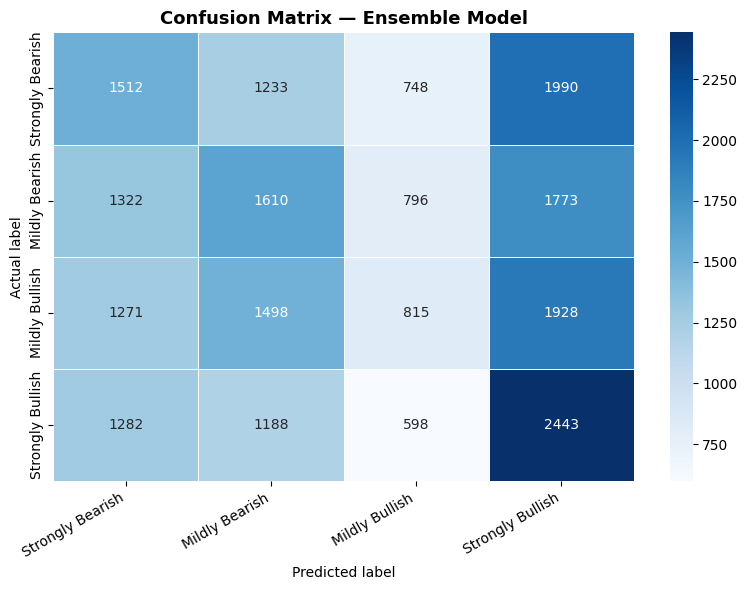

✅  Saved confusion_matrix.png


In [10]:
# ── Predict on the held-out test set ─────────────────────────────────────────
y_pred  = ensemble.predict(X_test)
y_proba = ensemble.predict_proba(X_test)   # shape: (n_samples, 4)

# ── Overall accuracy and weighted F1 ─────────────────────────────────────────
acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average='weighted')

print(f"🎯  Accuracy (overall)     : {acc*100:.2f}%")
print(f"📐  Weighted F1-score      : {f1:.4f}")
print(f"\n{'─'*60}")

# ── Per-class report ──────────────────────────────────────────────────────────
# precision = of all predicted X, how many were actually X
# recall    = of all actual X, how many did we catch
# f1-score  = harmonic mean of precision and recall
print("\n📋  Classification Report:\n")
print(classification_report(
    y_test, y_pred,
    target_names=[LABEL_MAP[k] for k in sorted(LABEL_MAP)]
))

# ── Confusion matrix ──────────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
labels = [LABEL_MAP[k] for k in sorted(LABEL_MAP)]

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=labels, yticklabels=labels,
    linewidths=0.5
)
plt.title('Confusion Matrix — Ensemble Model', fontsize=13, fontweight='bold')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅  Saved confusion_matrix.png")

In [11]:
# ── Why TimeSeriesSplit instead of KFold? ─────────────────────────────────────
# In time-series data, future data must NEVER appear in the training fold.
# TimeSeriesSplit creates 5 folds where each train fold is strictly earlier
# than its corresponding test fold — exactly like real trading.

tscv = TimeSeriesSplit(n_splits=5)

# Cross-validate only the XGBoost model (fastest of the three)
print("🔄  Running 5-fold TimeSeriesSplit cross-validation on XGBoost...")
cv_scores = cross_val_score(
    xgb,
    X_train_bal, y_train_bal,
    cv      = tscv,
    scoring = 'accuracy',
    n_jobs  = -1
)

print(f"\n   CV Fold Accuracies : {[f'{s*100:.1f}%' for s in cv_scores]}")
print(f"   Mean CV Accuracy   : {cv_scores.mean()*100:.2f}%")
print(f"   Std  CV Accuracy   : {cv_scores.std()*100:.2f}%")
print("\n   Low std = model is consistent across time periods ✅")

🔄  Running 5-fold TimeSeriesSplit cross-validation on XGBoost...

   CV Fold Accuracies : ['27.8%', '27.8%', '27.8%', '27.2%', '28.4%']
   Mean CV Accuracy   : 27.81%
   Std  CV Accuracy   : 0.39%

   Low std = model is consistent across time periods ✅


In [12]:
def predict_stock(ticker, df, model, scaler, features):
    """
    Takes the most recent row of a stock's feature DataFrame,
    scales it, runs it through the ensemble, and returns:
      - predicted label (0-3)
      - confidence % for that label
      - probability vector for all 4 classes
    """
    latest_row = df[features].iloc[-1:].copy()   # last available trading day
    latest_scaled = scaler.transform(latest_row)
    pred  = model.predict(latest_scaled)[0]
    proba = model.predict_proba(latest_scaled)[0]
    return int(pred), proba[pred] * 100, proba


# ── Predict for every stock ────────────────────────────────────────────────────
rows = []
for ticker, df in featured.items():
    try:
        pred, conf, proba = predict_stock(ticker, df, ensemble, scaler, FEATURES)
        rows.append({
            'Ticker'           : ticker.replace('.NS', ''),
            'Signal'           : LABEL_MAP[pred],
            'Confidence'       : f"{conf:.1f}%",
            'Strongly Bearish' : f"{proba[0]*100:.1f}%",
            'Mildly Bearish'   : f"{proba[1]*100:.1f}%",
            'Mildly Bullish'   : f"{proba[2]*100:.1f}%",
            'Strongly Bullish' : f"{proba[3]*100:.1f}%",
        })
    except Exception as e:
        print(f"⚠️  {ticker}: {e}")

results_df = pd.DataFrame(rows)

# ── Display sorted by signal strength ─────────────────────────────────────────
order = ["Strongly Bullish", "Mildly Bullish", "Mildly Bearish", "Strongly Bearish"]
results_df['_sort'] = results_df['Signal'].apply(lambda s: order.index(s))
results_df = results_df.sort_values('_sort').drop(columns='_sort').reset_index(drop=True)

print("\n" + "═"*80)
print("   📈  NIFTY 50 — CURRENT MARKET SIGNALS")
print("═"*80)
pd.set_option('display.max_rows', 60)
pd.set_option('display.width', 120)
print(results_df.to_string(index=False))

print("\n📊  Signal Summary:")
print(results_df['Signal'].value_counts().to_string())


════════════════════════════════════════════════════════════════════════════════
   📈  NIFTY 50 — CURRENT MARKET SIGNALS
════════════════════════════════════════════════════════════════════════════════
    Ticker           Signal Confidence Strongly Bearish Mildly Bearish Mildly Bullish Strongly Bullish
       TCS Strongly Bullish      34.8%            15.5%          16.4%          33.3%            34.8%
  HDFCBANK Strongly Bullish      27.2%            25.9%          20.0%          26.8%            27.2%
    MARUTI Strongly Bullish      32.9%            25.4%          15.9%          25.8%            32.9%
        LT Strongly Bullish      27.7%            22.5%          25.1%          24.7%            27.7%
   HCLTECH Strongly Bullish      31.5%            20.0%          21.8%          26.6%            31.5%
     WIPRO Strongly Bullish      25.8%            25.6%          24.8%          23.8%            25.8%
 BRITANNIA Strongly Bullish      31.1%            26.6%          17.4%      

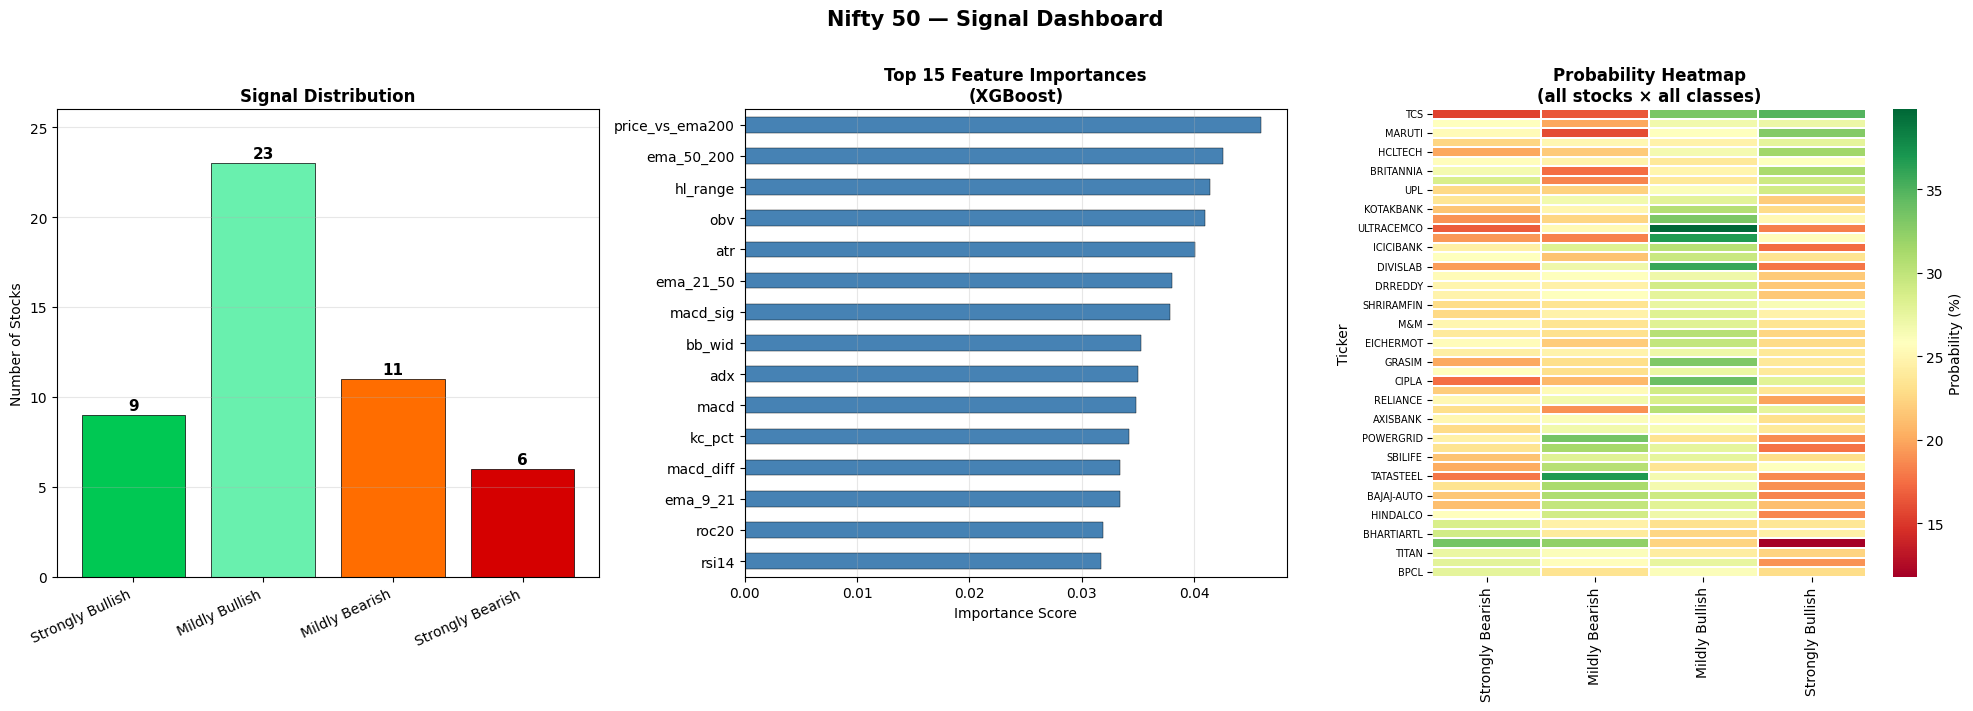

✅  Dashboard saved as nifty50_dashboard.png


In [13]:
# ── Figure with 3 subplots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('Nifty 50 — Signal Dashboard', fontsize=15, fontweight='bold', y=1.01)

# ── Plot 1: Signal count bar chart ────────────────────────────────────────────
color_map = {
    'Strongly Bullish': '#00C853',
    'Mildly Bullish'  : '#69F0AE',
    'Mildly Bearish'  : '#FF6D00',
    'Strongly Bearish': '#D50000'
}
counts = results_df['Signal'].value_counts().reindex(order, fill_value=0)
bars   = axes[0].bar(counts.index, counts.values,
                     color=[color_map[s] for s in counts.index],
                     edgecolor='black', linewidth=0.5)

for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(val), ha='center', va='bottom', fontsize=11, fontweight='bold')

axes[0].set_title('Signal Distribution', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Stocks')
axes[0].set_xticklabels(counts.index, rotation=25, ha='right', fontsize=10)
axes[0].set_ylim(0, counts.max() + 3)
axes[0].grid(axis='y', alpha=0.3)

# ── Plot 2: Top 15 feature importances from XGBoost ──────────────────────────
feat_imp = pd.Series(
    ensemble.estimators_[0].feature_importances_,   # index 0 = xgb
    index=FEATURES
).nlargest(15).sort_values()

feat_imp.plot(kind='barh', ax=axes[1], color='steelblue', edgecolor='black', linewidth=0.3)
axes[1].set_title('Top 15 Feature Importances\n(XGBoost)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].grid(axis='x', alpha=0.3)

# ── Plot 3: Heatmap — probability matrix for all stocks ───────────────────────
prob_cols   = ['Strongly Bearish','Mildly Bearish','Mildly Bullish','Strongly Bullish']
prob_matrix = results_df[['Ticker'] + prob_cols].set_index('Ticker')
prob_matrix = prob_matrix.apply(lambda col: col.str.replace('%','').astype(float))

sns.heatmap(
    prob_matrix, ax=axes[2],
    cmap='RdYlGn',        # red = bearish probability, green = bullish
    linewidths=0.3,
    cbar_kws={'label': 'Probability (%)'},
    annot=False           # set True if you want numbers inside each cell
)
axes[2].set_title('Probability Heatmap\n(all stocks × all classes)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('')
axes[2].tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.savefig('nifty50_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅  Dashboard saved as nifty50_dashboard.png")